# 06 · H1: perfiles monetario-fiscales y heterogeneidad de las trayectorias inflacionarias

**Hipótesis 1.** Compartir un perfil monetario-fiscal no implica compartir la trayectoria inflacionaria: dentro de grupos de países monetario-fiscalmente similares, la inflación sigue siendo heterogénea.

**Diseño** (`src/inflacion/clustering.py`, `pipeline/run_clustering.py`):

1. Espacio de clustering: los 36 componentes principales monetarios (media, tendencia y volatilidad).
2. Atípicos: distancia euclídea al centroide por encima de Q3 + 1,5·RIC (Tukey). Se excluyen del ajuste.
3. Grilla: K-means, jerárquico (ward, average, complete) y GMM (diag, tied, spherical), con k de 3 a 8.
4. **Regla de selección, fijada antes de ver los resultados**: descartar las configuraciones con algún grupo de menos de 5 países o con estabilidad bootstrap (ARI medio en submuestras del 80%) menor a 0,60. Entre las restantes, la de mayor silhouette.
5. Prueba de H1: proporción de la variación de cada estadístico de inflación explicada por el grupo (η² sobre la escala transformada, con p-valor por permutación) y Kruskal-Wallis. H1 se sostiene si la mayor parte de la variación queda **dentro** de los grupos.

La inflación **no** interviene en la formación de los grupos: se excluyeron el IPC, los deflactores y los índices de precios de todas las features.

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from inflacion.config import Paths, load_params
from inflacion.viz import CATEGORICAL, CLUSTER_COLORS, DIM_LABELS, DIMENSION_COLORS, apply_theme, heatmap, show, subtitle
from inflacion.viz.theme import DIVERGING, INK_MUTED, INK_SECONDARY, SEQUENTIAL_BLUE

apply_theme()
P = load_params()
D = Paths.processed
pd.set_option("display.precision", 3)
import json
from inflacion.sources.countries import un_members

members = un_members().set_index("iso3")
summary = json.loads((D / "clustering_resumen.json").read_text())
grid = pd.read_csv(D / "clustering_grid.csv")
labels = pd.read_csv(D / "clusters.csv", index_col=0)["cluster"]
dist = pd.read_csv(D / "clustering_distancias.csv", index_col=0)
target = pd.read_csv(D / "target_principal.csv", index_col="iso3")
scores = pd.read_parquet(D / "pca_scores.parquet")
Xm = scores[[c for c in scores.columns if c.startswith("MONETARIA_")]]
print(f"Espacio: {Xm.shape[1]} componentes · {len(dist)} países · atípicos: {len(summary['atipicos'])} · países agrupados: {summary['n_cluster']}")
print("Configuración elegida:", summary["config"])

Espacio: 36 componentes · 183 países · atípicos: 8 · países agrupados: 175
Configuración elegida: {'algoritmo': 'KMeans', 'parametro': '-', 'k': 5, 'silhouette': 0.1439690200621935, 'ari_bootstrap': 0.8235169313127255}


## 1. Atípicos en el espacio monetario

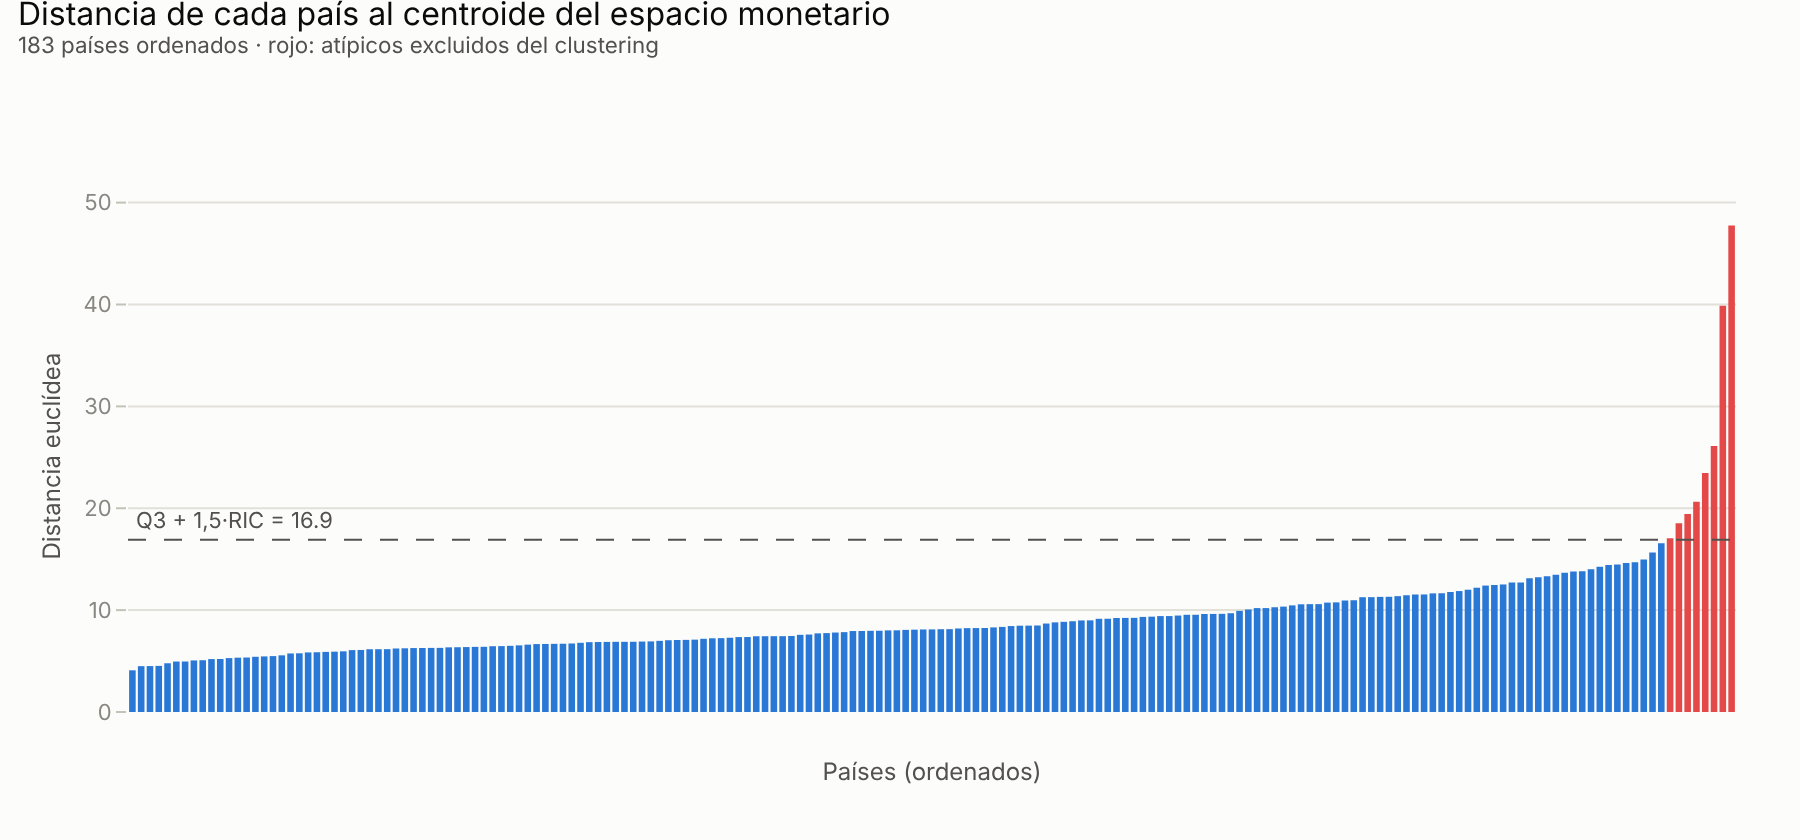

Timor-Leste (47.7), Sierra Leone (39.9), Zimbabwe (26.1), Libya (23.5), Eritrea (20.6), South Sudan (19.4), Kiribati (18.5), Iceland (17.1)


In [2]:
d = dist.sort_values("distancia_centroide")
fig = go.Figure(go.Bar(x=np.arange(len(d)), y=d["distancia_centroide"], marker_color=np.where(d["atipico"], CATEGORICAL[7], CATEGORICAL[0]),
                       customdata=members.loc[d.index, "pais"], hovertemplate="%{customdata}: %{y:.1f}<extra></extra>"))
fig.add_hline(y=summary["umbral_tukey"], line=dict(color=INK_SECONDARY, dash="dash", width=1))
fig.add_annotation(x=0, y=summary["umbral_tukey"], text=f"Q3 + 1,5·RIC = {summary['umbral_tukey']:.1f}", showarrow=False,
                   xanchor="left", yshift=10, font=dict(size=11, color=INK_SECONDARY))
fig.update_layout(title=subtitle("Distancia de cada país al centroide del espacio monetario", "183 países ordenados · rojo: atípicos excluidos del clustering"),
                  xaxis=dict(showticklabels=False, showgrid=False, ticks="", title="Países (ordenados)"), yaxis_title="Distancia euclídea")
show(fig, "06_atipicos", height=420)
print(", ".join(f"{members.loc[i, 'pais']} ({v:.1f})" for i, v in d[d["atipico"]]["distancia_centroide"][::-1].items()))

**Interpretación.** Ocho países quedan por encima del umbral de Tukey. Timor-Leste (47,7) y Sierra Leona (39,9) están muy lejos del resto: sus series fiscales y monetarias reflejan economías de posconflicto con financiamiento externo extraordinario. Les siguen Zimbabue, Libia, Eritrea y Sudán del Sur, con colapsos monetarios o conflictos armados, Kiribati, con una estructura fiscal atípica de microestado, e Islandia, por la crisis bancaria de 2008. Dejarlos en el ajuste haría que un grupo se dedicara a capturar a un solo país. Se excluyen del clustering y se reincorporan en las regresiones de robustez (notebook 08).

## 2. Selección de la configuración

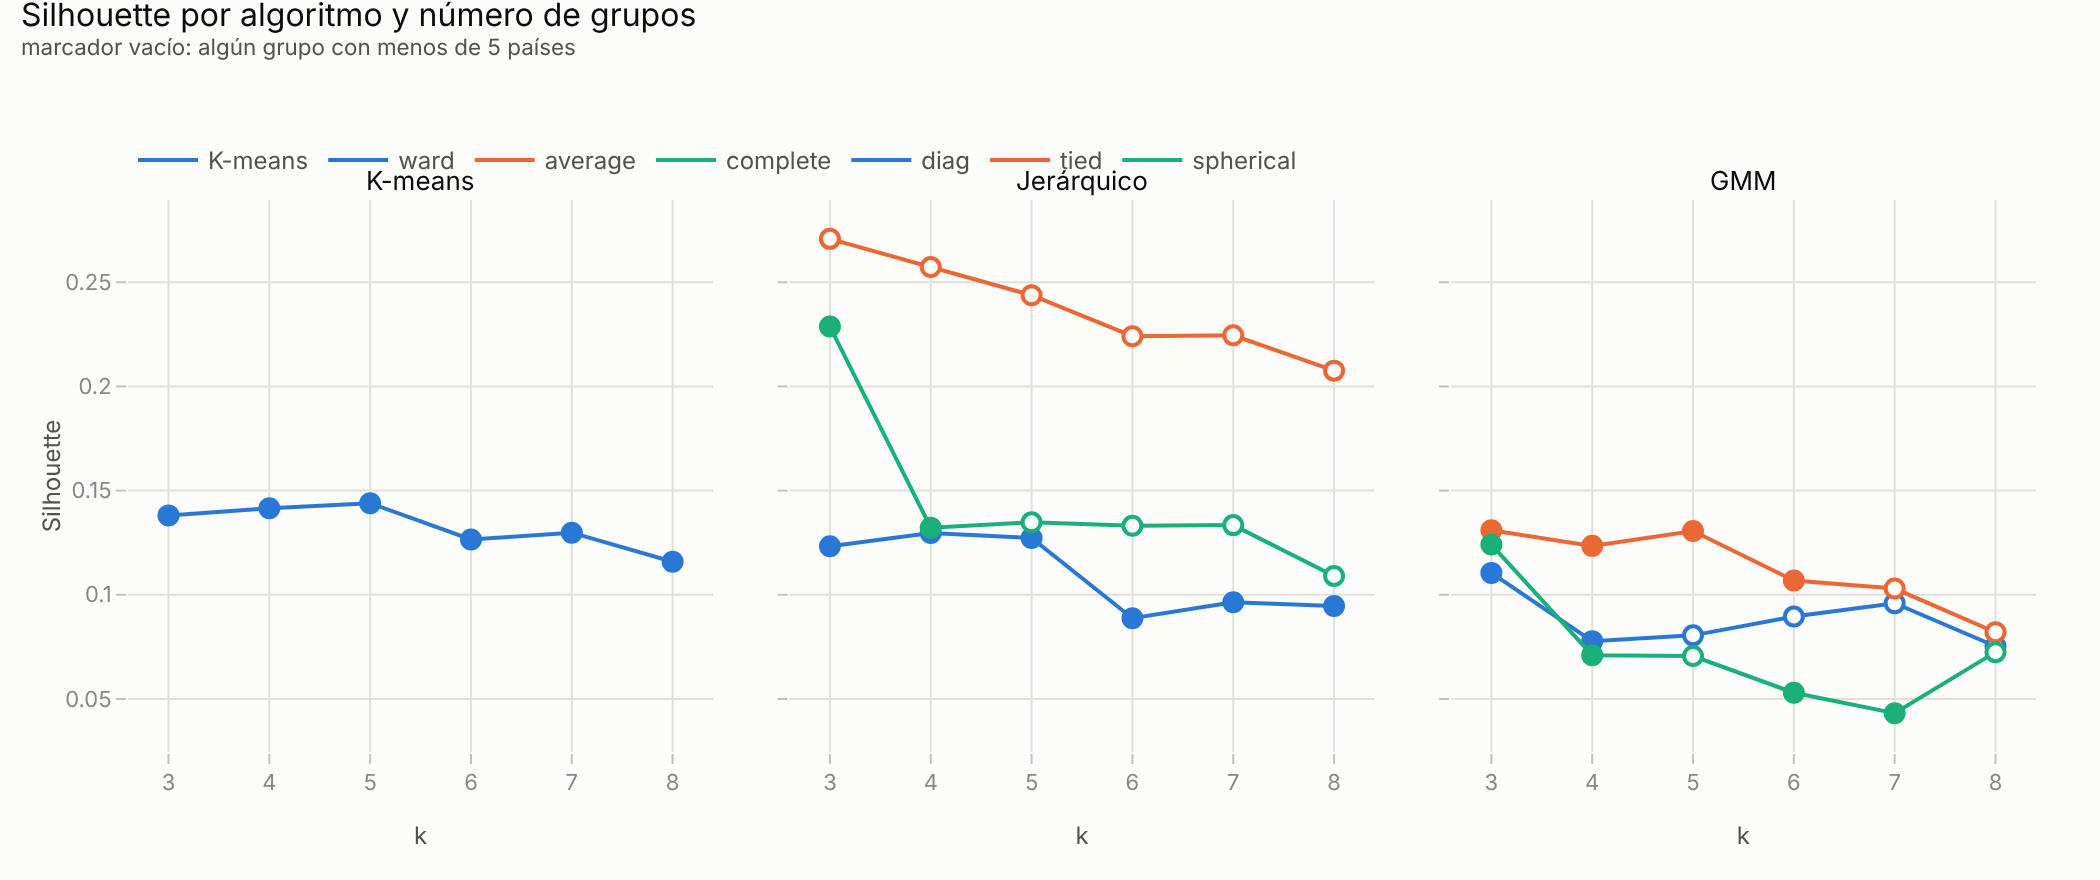

Rango de silhouette en la grilla: 0.043 – 0.271


In [3]:
fam = {"KMeans": ["-"], "Jerarquico": ["ward", "average", "complete"], "GMM": ["diag", "tied", "spherical"]}
fig = make_subplots(rows=1, cols=3, subplot_titles=("K-means", "Jerárquico", "GMM"), shared_yaxes=True, horizontal_spacing=0.04)
for c, (algo, params) in enumerate(fam.items(), start=1):
    for i, prm in enumerate(params):
        g = grid[(grid["algoritmo"] == algo) & (grid["parametro"] == prm)].sort_values("k")
        ok = g["tam_min"] >= P["clustering"]["tamanio_minimo"]
        nm = "K-means" if prm == "-" else prm
        fig.add_scatter(x=g["k"], y=g["silhouette"], mode="lines", line=dict(color=CATEGORICAL[i], width=2), name=nm,
                        legendgroup=nm, showlegend=True, hoverinfo="skip", row=1, col=c)
        fig.add_scatter(x=g["k"], y=g["silhouette"], mode="markers", legendgroup=nm, showlegend=False,
                        marker=dict(size=9, color=np.where(ok, CATEGORICAL[i], "#fcfcfb"), line=dict(color=CATEGORICAL[i], width=2)),
                        customdata=g["tam_min"], hovertemplate=nm + " k=%{x}: silhouette %{y:.3f} · grupo mínimo %{customdata}<extra></extra>", row=1, col=c)
fig.update_yaxes(title_text="Silhouette", row=1, col=1)
fig.update_xaxes(title_text="k", dtick=1)
fig.update_annotations(font_size=13)
fig.update_layout(title=subtitle("Silhouette por algoritmo y número de grupos", "marcador vacío: algún grupo con menos de 5 países"))
show(fig, "06_grilla_silhouette", width=1050, height=440)
print(f"Rango de silhouette en la grilla: {grid['silhouette'].min():.3f} – {grid['silhouette'].max():.3f}")

**Interpretación.** Todas las configuraciones tienen silhouette baja (0,04-0,27). **El espacio monetario-fiscal no tiene grupos naturales bien separados**: los países se distribuyen en un continuo, con zonas de mayor densidad. Las silhouettes más altas corresponden casi siempre a soluciones degeneradas, con un grupo enorme y otros de 6 o 7 países. Esto ya condiciona la lectura de H1: los grupos son una partición útil del continuo, no tipos discretos.

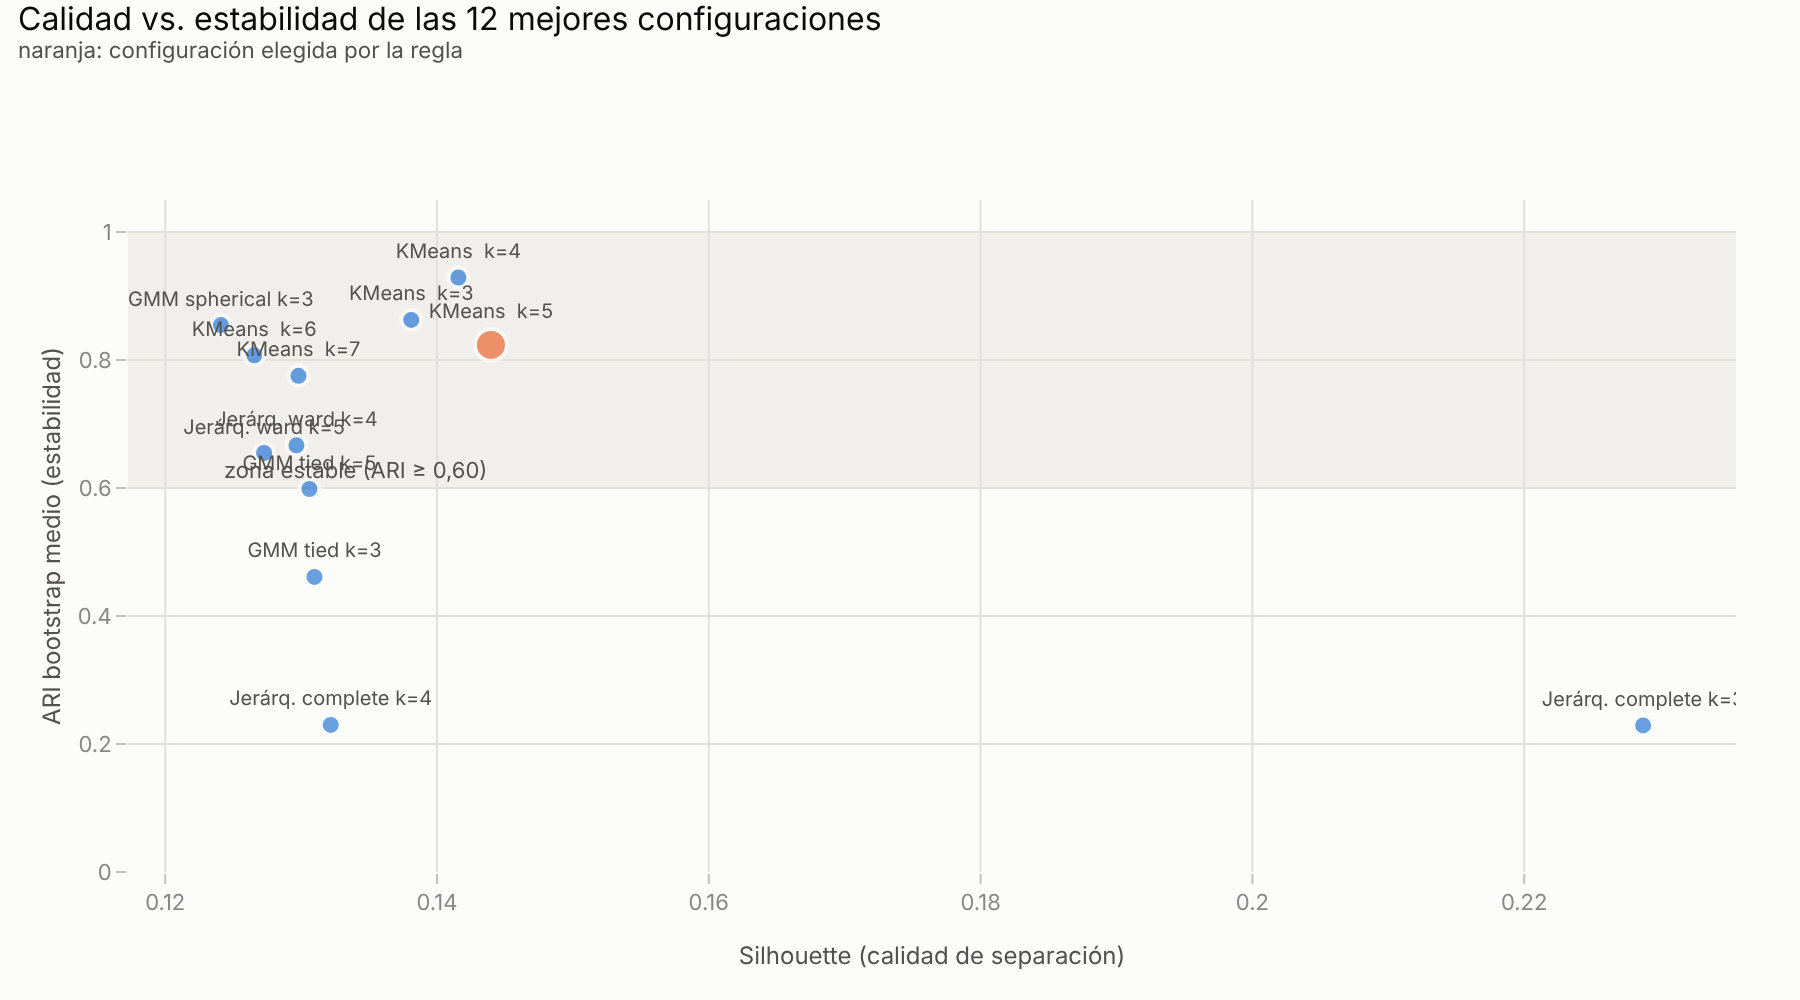

,config,silhouette,davies_bouldin,tam_min,ari_bootstrap
18,Jerárq. complete k=3,0.229,1.926,6,0.229
2,KMeans k=5,0.144,1.852,7,0.824
1,KMeans k=4,0.142,2.045,22,0.929
0,KMeans k=3,0.138,2.220,30,0.863
19,Jerárq. complete k=4,0.132,1.997,6,0.230
30,GMM tied k=3,0.131,2.325,35,0.461
32,GMM tied k=5,0.131,1.879,7,0.598
4,KMeans k=7,0.130,1.963,5,0.775
7,Jerárq. ward k=4,0.130,2.131,26,0.667
8,Jerárq. ward k=5,0.127,1.952,6,0.655


In [4]:
top = grid.dropna(subset=["ari_bootstrap"]).copy()
top["config"] = top["algoritmo"].str.replace("Jerarquico", "Jerárq.") + " " + top["parametro"].replace("-", "") + " k=" + top["k"].astype(str)
chosen = (top["algoritmo"] == summary["config"]["algoritmo"]) & (top["k"] == summary["config"]["k"]) & (top["parametro"] == summary["config"]["parametro"])
fig = go.Figure()
fig.add_hrect(y0=P["clustering"]["ari_minimo"], y1=1.0, fillcolor="#f0efec", line_width=0, layer="below")
fig.add_scatter(x=top["silhouette"], y=top["ari_bootstrap"], mode="markers+text", text=top["config"], textposition="top center",
                textfont=dict(size=10, color=INK_SECONDARY), marker=dict(size=np.where(chosen, 16, 10), color=np.where(chosen, CATEGORICAL[1], CATEGORICAL[0]),
                line=dict(color="#fcfcfb", width=2)), hovertemplate="%{text}<br>silhouette %{x:.3f} · ARI %{y:.2f}<extra></extra>", showlegend=False)
fig.add_annotation(x=top["silhouette"].min(), y=P["clustering"]["ari_minimo"], text="zona estable (ARI ≥ 0,60)", showarrow=False,
                   xanchor="left", yanchor="bottom", font=dict(size=11, color=INK_SECONDARY))
fig.update_layout(title=subtitle("Calidad vs. estabilidad de las 12 mejores configuraciones", "naranja: configuración elegida por la regla"),
                  xaxis_title="Silhouette (calidad de separación)", yaxis=dict(title="ARI bootstrap medio (estabilidad)", range=[0, 1.05]))
show(fig, "06_estabilidad_vs_silhouette", height=500)
top[["config", "silhouette", "davies_bouldin", "tam_min", "ari_bootstrap"]].sort_values("silhouette", ascending=False).round(3)

**Interpretación.** La mayor silhouette (jerárquico complete con k=3, 0,229) es también una de las más inestables: un ARI de 0,23 significa que, con otra submuestra del 80% de los países, la partición cambia casi por completo. GMM tied, la configuración elegida en la tesis original, también queda por debajo del umbral de estabilidad (ARI de 0,46 a 0,61 según k). La regla elige **K-means con k = 5**: silhouette 0,144, prácticamente igual a la de k = 3 y k = 4, y estabilidad alta (ARI 0,82).

**Diferencia con la tesis.** La configuración final cambia de GMM tied k=4 a K-means k=5. La razón es metodológica: la estabilidad pasa a ser un criterio explícito. Las conclusiones de H1 no dependen de esta elección (sección 5).

## 3. Perfiles de los grupos

Mediana de cada grupo en indicadores monetario-fiscales seleccionados, expresada como percentil entre los 183 países (50 = país típico). Se usan percentiles porque los valores extremos de algunos países (por ejemplo, el crecimiento del dinero en hiperinflaciones) distorsionarían una escala en desvíos estándar. Los nombres de los grupos se asignaron **después** de inspeccionar estos perfiles y su composición.

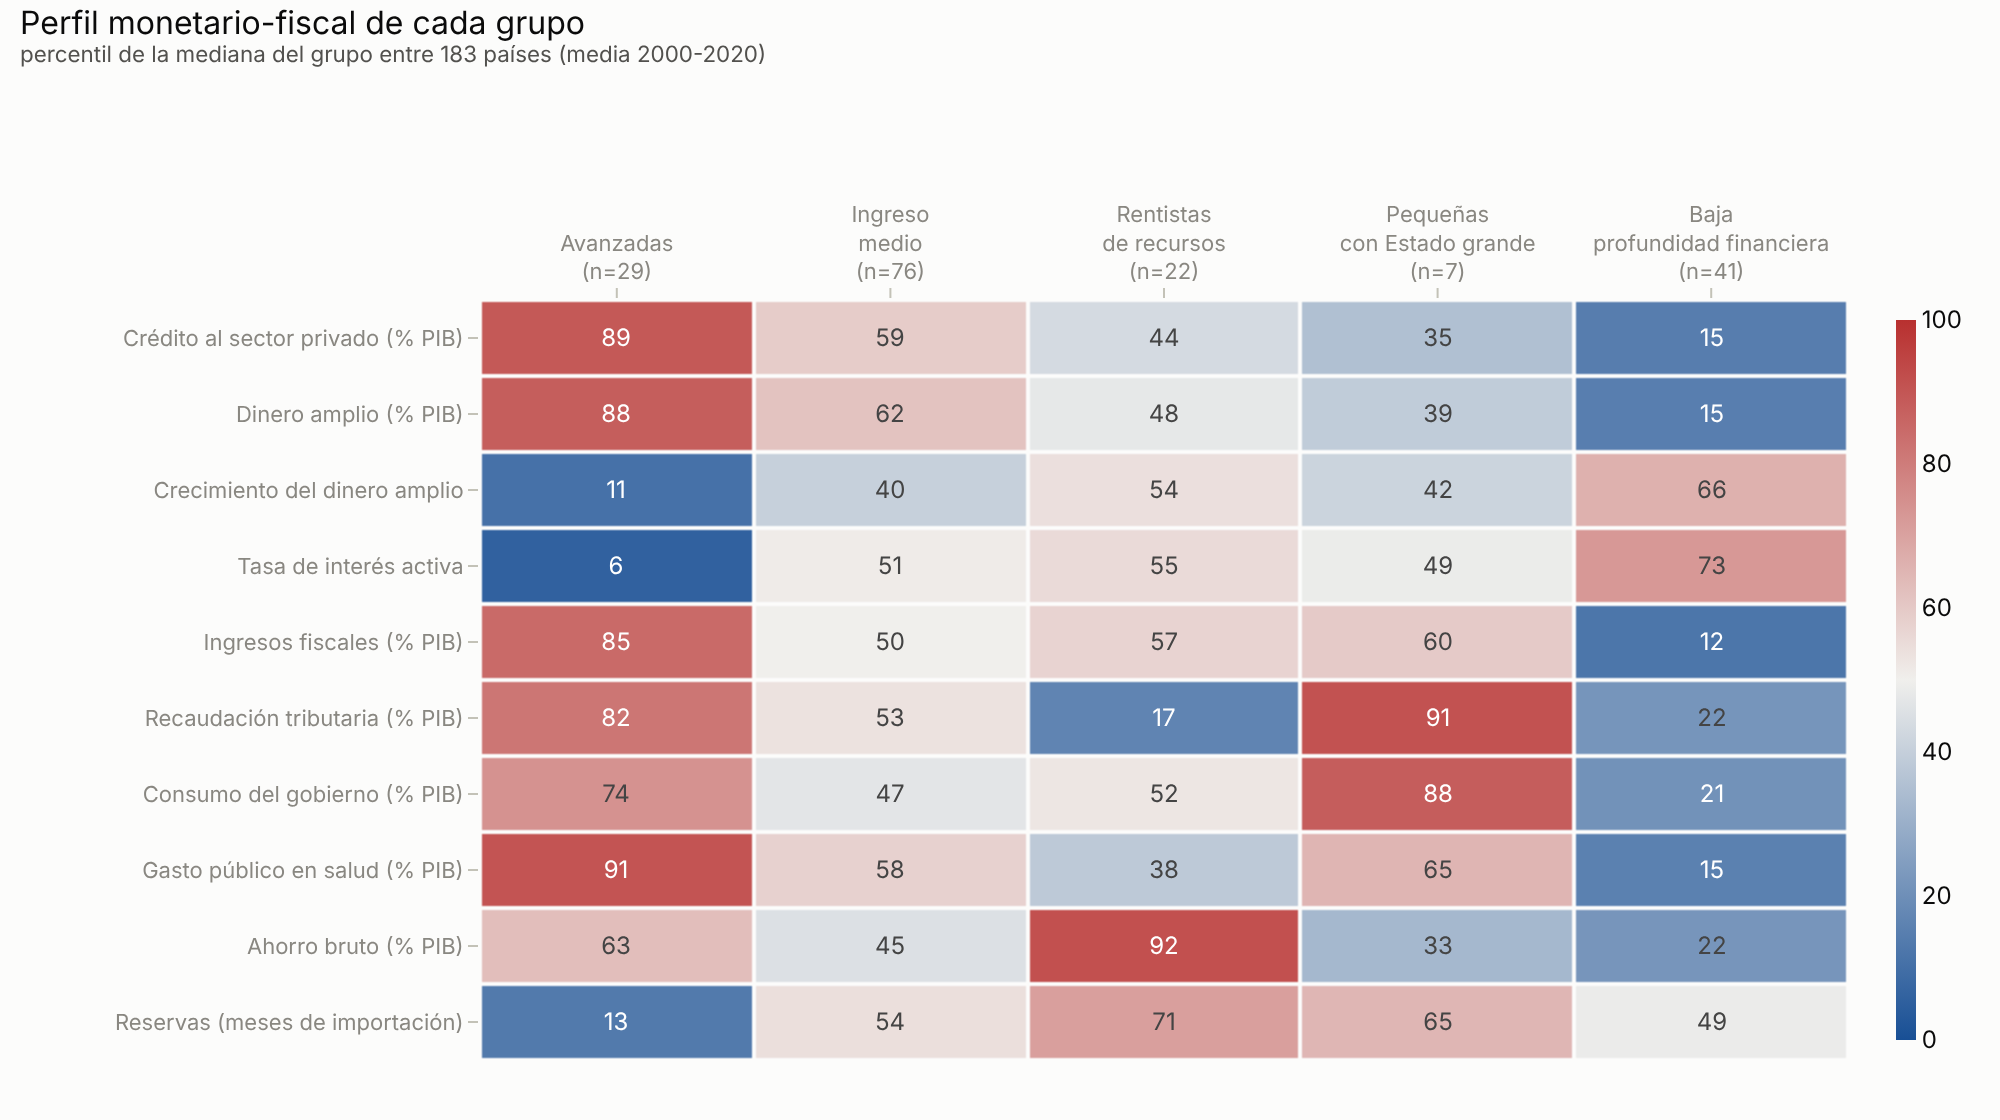

Avanzadas (29): Australia, Austria, Belgium, Canada, Cyprus, Czechia, Denmark, Estonia, Finland, France, Germany, Greece, Ireland, Israel, Italy, Japan, Luxembourg, Malta, Netherlands (Kingd, New Zealand, Norway, Portugal, Republic of Korea, Slovenia, Spain, Sweden, Switzerland, United Kingdom of , United States of A
Ingreso medio (76): Albania, Antigua and Barbud, Argentina, Bahamas, Barbados, Belarus, Belize, Bolivia (Plurinati, Bosnia and Herzego, Brazil, Bulgaria, Cabo Verde, Chile, China, Colombia, Costa Rica, Croatia, Cuba, Djibouti, Dominica, Dominican Republic, Ecuador, Egypt, El Salvador, Fiji, Georgia, Grenada, Guatemala, Guyana, Honduras, Hungary, India, Indonesia, Iran (Islamic Repu, Jamaica, Jordan, Kazakhstan, Kyrgyzstan, Latvia, Lebanon, Lithuania, Malaysia, Mauritius, Mexico, Montenegro, Morocco, Nepal, Nicaragua, North Macedonia, Panama, Papua New Guinea, Paraguay, Peru, Philippines, Poland, Republic of Moldov, Romania, Russian Federation, Saint Kitts and Ne, Saint Luc

In [5]:
X = pd.read_parquet(D / "features_crudas.parquet")
NAMES = {2: "Avanzadas", 3: "Rentistas de recursos", 0: "Ingreso medio", 1: "Baja profundidad financiera", 4: "Pequeñas con Estado grande"}
order = [2, 0, 3, 4, 1]
ind = {"FS.AST.PRVT.GD.ZS": "Crédito al sector privado (% PIB)", "FM.LBL.BMNY.GD.ZS": "Dinero amplio (% PIB)",
       "FM.LBL.BMNY.ZG": "Crecimiento del dinero amplio", "FR.INR.LEND": "Tasa de interés activa",
       "GC.REV.XGRT.GD.ZS": "Ingresos fiscales (% PIB)", "GC.TAX.TOTL.GD.ZS": "Recaudación tributaria (% PIB)",
       "NE.CON.GOVT.ZS": "Consumo del gobierno (% PIB)", "SH.XPD.GHED.GD.ZS": "Gasto público en salud (% PIB)",
       "NY.GNS.ICTR.ZS": "Ahorro bruto (% PIB)", "FI.RES.TOTL.MO": "Reservas (meses de importación)"}
Zr = X[[f"{c}__media" for c in ind]].rank(pct=True).mul(100)
prof = Zr.loc[labels.index].groupby(labels).median().T
prof.index = list(ind.values())
prof = prof[order]
prof.columns = [f"{NAMES[k].replace(' ', '<br>', 1)}<br>(n={int((labels == k).sum())})" for k in order]
fig = heatmap(prof, subtitle("Perfil monetario-fiscal de cada grupo", "percentil de la mediana del grupo entre 183 países (media 2000-2020)"),
              colorscale=DIVERGING, zmid=50, zmin=0, zmax=100, fmt=".0f")
fig.update_layout(margin=dict(l=240, b=30, t=150), xaxis=dict(tickangle=0, side="top"))
show(fig, "06_perfiles_grupos", width=1000, height=560)
for k in order:
    idx = labels[labels == k].index
    print(f"{NAMES[k]} ({len(idx)}): " + ", ".join(sorted(members.loc[idx, "pais"].str.slice(0, 18))))

**Interpretación de los grupos.**

- **Avanzadas (29)**: Europa occidental, Norteamérica, Japón, Corea, Australia, Israel. Máxima profundidad financiera (crédito y dinero en los percentiles 88-89), alta presión fiscal y gasto social, tasas de interés y crecimiento monetario mínimos. Pocas reservas, porque emiten monedas de reserva o pertenecen a uniones monetarias.
- **Ingreso medio (76)**: América Latina, Europa del Este, Asia emergente, Norte de África. Valores intermedios en casi todo. Es el grupo más grande y más heterogéneo.
- **Rentistas de recursos (22)**: el Golfo, Asia Central, petroleras africanas, Venezuela, Singapur. Ahorro nacional muy alto (percentil 92) con recaudación tributaria baja (percentil 17): el Estado se financia con la renta de los recursos y no con impuestos.
- **Pequeñas con Estado grande (7)**: Lesotho, Eswatini y Namibia (unión aduanera del África austral) más pequeños Estados insulares. Recaudación (percentil 91) y consumo público (88) altos, sector financiero chico.
- **Baja profundidad financiera (41)**: sobre todo África subsahariana, más Afganistán, Haití y Bangladesh. Crédito, dinero y recaudación en el percentil 12-22, tasas de interés y crecimiento monetario altos.

Los grupos se parecen a los de la tesis original (avanzadas, rentistas, un grupo amplio heterogéneo), lo que sugiere que esta partición del espacio monetario-fiscal es robusta a los cambios del pipeline.

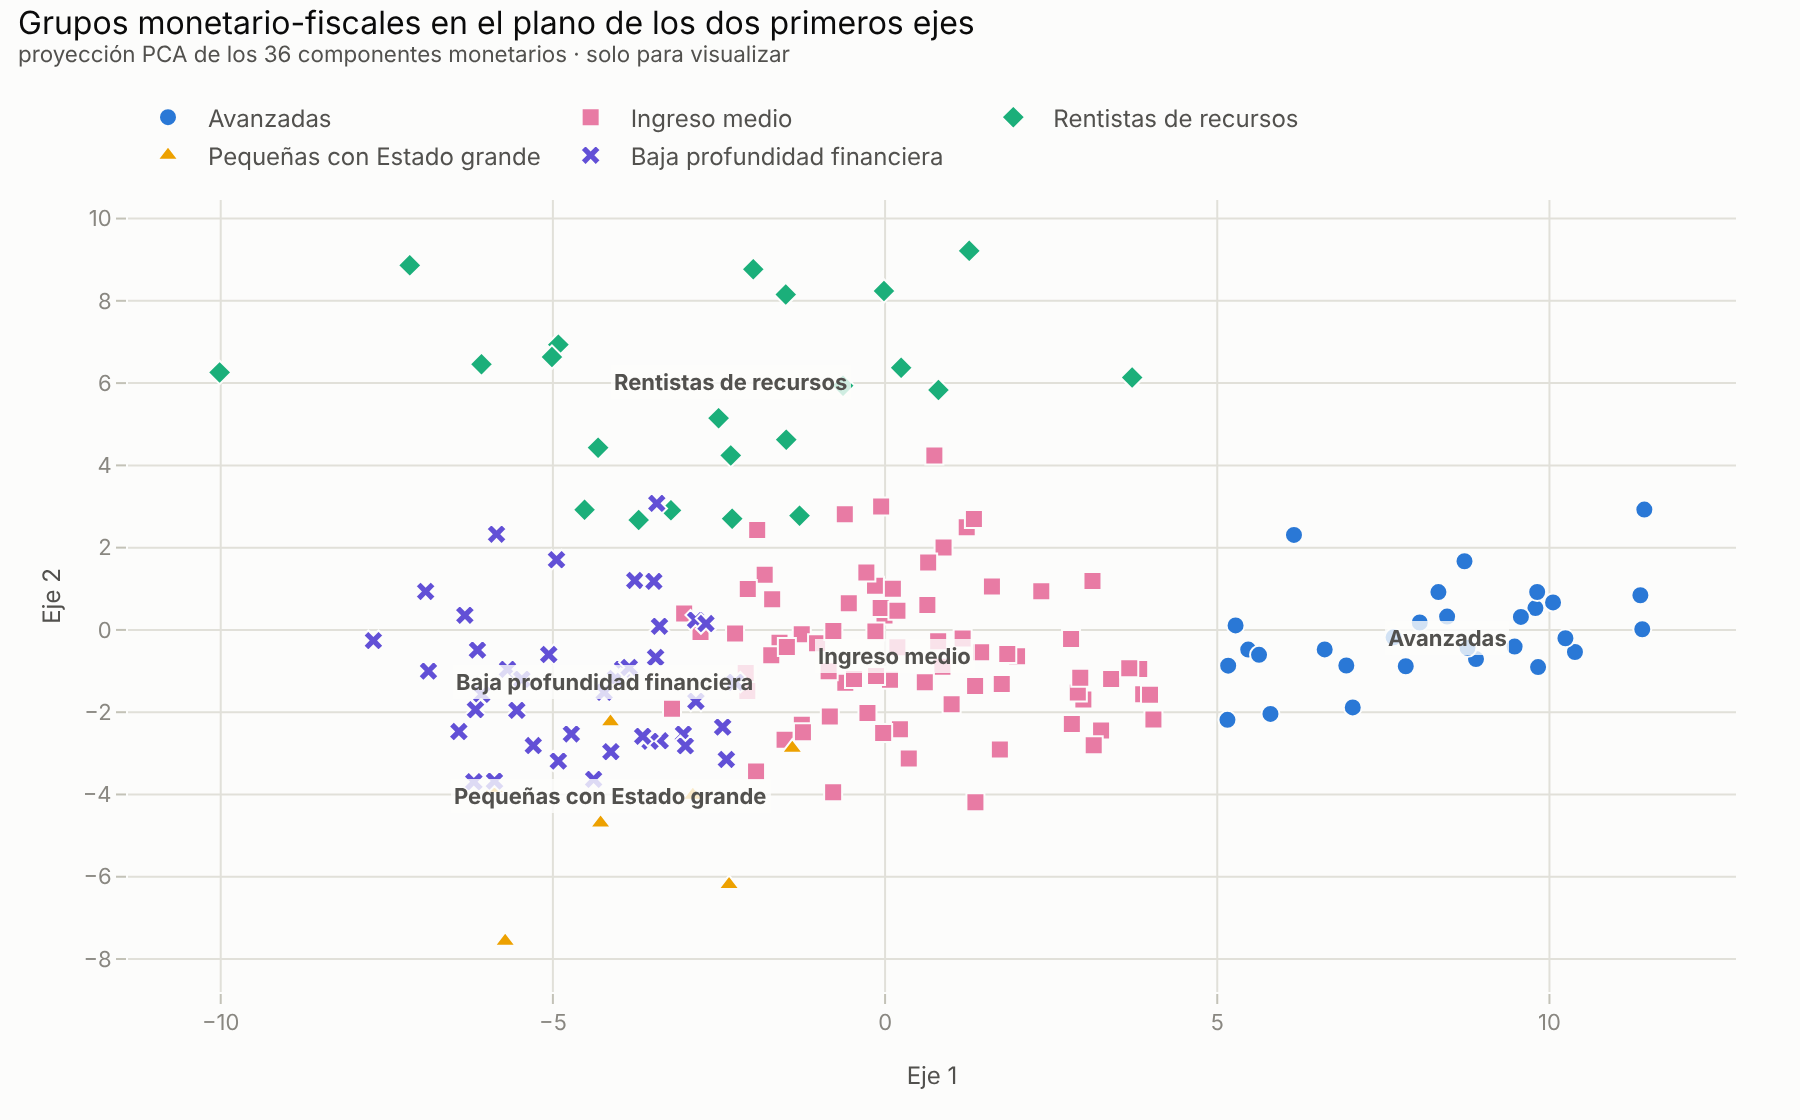

In [6]:
from sklearn.decomposition import PCA as PCA2
xy = pd.DataFrame(PCA2(2, random_state=0).fit_transform(Xm.loc[labels.index]), index=labels.index, columns=["d1", "d2"])
palette = {2: CATEGORICAL[0], 0: CATEGORICAL[4], 3: CATEGORICAL[2], 4: CATEGORICAL[3], 1: CATEGORICAL[6]}
symbols = {2: "circle", 0: "square", 3: "diamond", 4: "triangle-up", 1: "x"}
fig = go.Figure()
for k in order:
    g = xy[labels == k]
    fig.add_scatter(x=g["d1"], y=g["d2"], mode="markers", name=NAMES[k], marker=dict(size=9, color=palette[k], symbol=symbols[k],
                    line=dict(color="#fcfcfb", width=1)), customdata=members.loc[g.index, "pais"],
                    hovertemplate="%{customdata}<extra>" + NAMES[k] + "</extra>")
    fig.add_annotation(x=g["d1"].median(), y=g["d2"].median(), text=f"<b>{NAMES[k]}</b>", showarrow=False, font=dict(size=11, color=INK_SECONDARY),
                       bgcolor="rgba(252,252,251,0.8)")
fig.update_layout(title=subtitle("Grupos monetario-fiscales en el plano de los dos primeros ejes", "proyección PCA de los 36 componentes monetarios · solo para visualizar"),
                  xaxis_title="Eje 1", yaxis_title="Eje 2")
show(fig, "06_proyeccion_grupos", height=560)

mapa = go.Figure(go.Choropleth(locations=labels.index, z=[order.index(k) for k in labels], text=[NAMES[k] for k in labels],
                               colorscale=[[i / 4, palette[k]] for i, k in enumerate(order)], showscale=False,
                               hovertemplate="%{location} · %{text}<extra></extra>", marker_line_color="#fcfcfb"))
mapa.update_layout(title="Grupos monetario-fiscales", geo=dict(showframe=False, projection_type="natural earth"))
mapa.write_html(Paths.figures / "06_mapa_grupos.html", include_plotlyjs="cdn")

## 4. Prueba de H1: ¿cuánta variación inflacionaria queda dentro de los grupos?

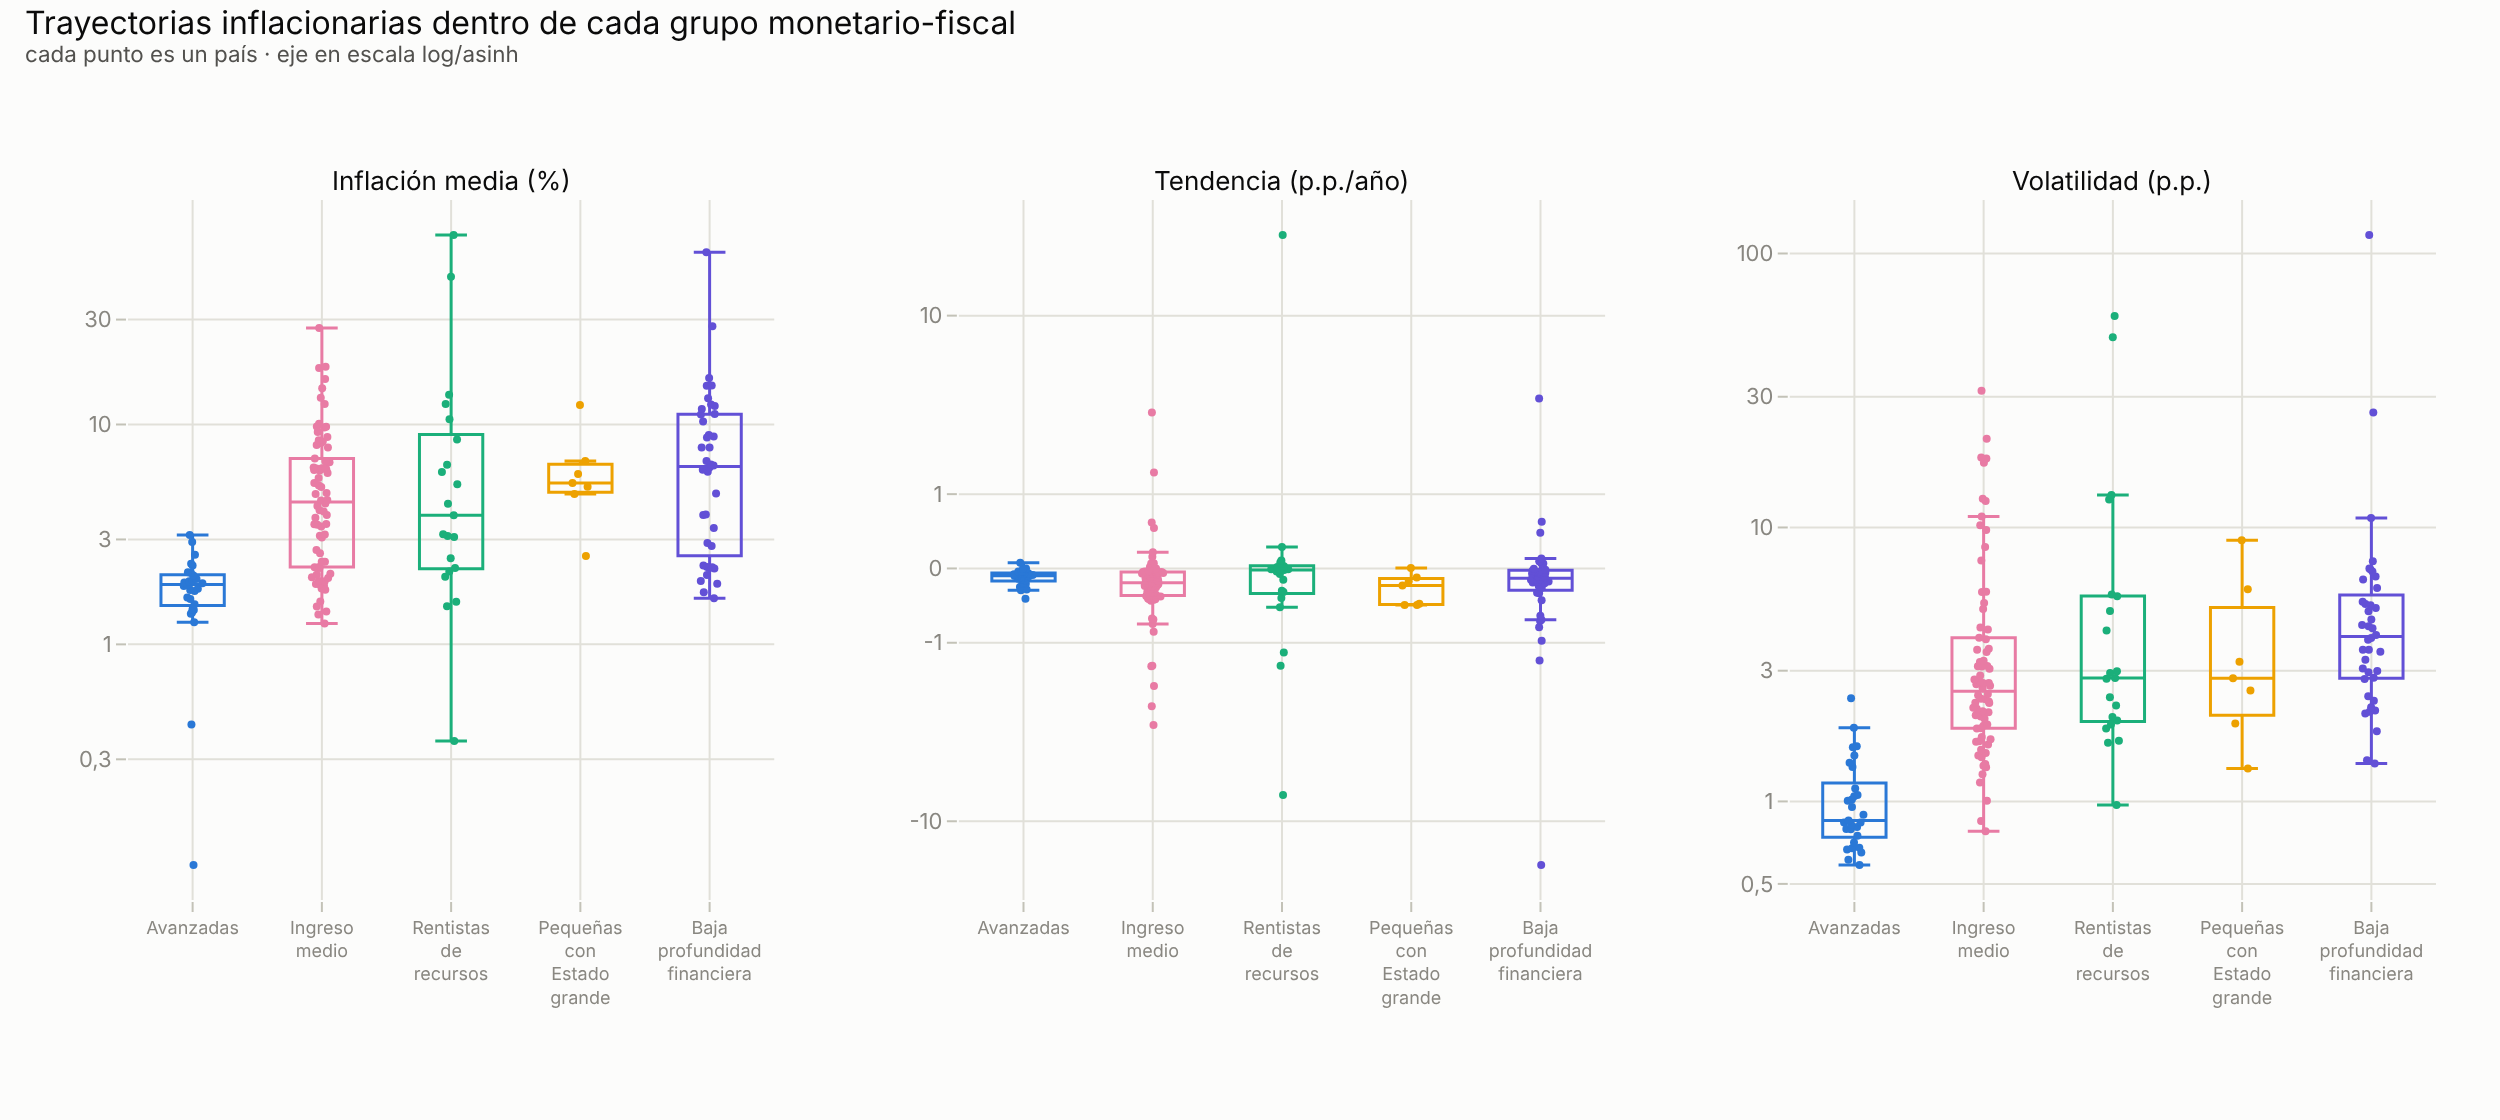

In [7]:
TR = {"media": np.log, "tendencia": np.arcsinh, "volatilidad": np.log}
TIT = {"media": "Inflación media (%)", "tendencia": "Tendencia (p.p./año)", "volatilidad": "Volatilidad (p.p.)"}
y = target.loc[labels.index]
fig = make_subplots(rows=1, cols=3, subplot_titles=list(TIT.values()), horizontal_spacing=0.08)
for c, stat in enumerate(TIT, start=1):
    for k in order:
        v = y.loc[labels[labels == k].index, stat].dropna()
        fig.add_box(y=TR[stat](v), name=NAMES[k].replace(" ", "<br>"), boxpoints="all", jitter=0.35, pointpos=0,
                    marker=dict(size=4, color=palette[k]), line=dict(color=palette[k], width=1.5), fillcolor="rgba(0,0,0,0)",
                    customdata=np.c_[members.loc[v.index, "pais"], v.values], showlegend=False,
                    hovertemplate="%{customdata[0]}: %{customdata[1]:.2f}<extra></extra>", row=1, col=c)
ticks = {"media": [0.3, 1, 3, 10, 30], "volatilidad": [0.5, 1, 3, 10, 30, 100], "tendencia": [-10, -1, 0, 1, 10]}
for c, stat in enumerate(TIT, start=1):
    fig.update_yaxes(tickvals=TR[stat](np.array(ticks[stat], dtype=float)), ticktext=[str(t).replace(".", ",") for t in ticks[stat]], row=1, col=c)
    fig.update_xaxes(tickfont=dict(size=9), tickangle=0, row=1, col=c)
fig.update_annotations(font_size=13)
fig.update_layout(title=subtitle("Trayectorias inflacionarias dentro de cada grupo monetario-fiscal", "cada punto es un país · eje en escala log/asinh"))
fig.update_layout(margin=dict(b=110))
show(fig, "06_h1_inflacion_por_grupo", width=1250, height=560)

**Interpretación.** Las diferencias entre grupos son visibles, sobre todo en la volatilidad. Las avanzadas tienen inflación baja (mediana 1,9%) y muy poco volátil (0,9 p.p.), y los de baja profundidad financiera, la más alta (6,4% y 4,0 p.p.). Pero lo que domina es la dispersión **dentro** de cada grupo. En "ingreso medio" la inflación media va de 1,2% a 27,5%. En "rentistas", de 0,4% (Brunéi) a 72,7% (Venezuela). En "baja profundidad financiera", de 1,6% a 60,7% (Congo RD). Solo las avanzadas forman un grupo homogéneo. La tendencia es prácticamente igual entre grupos: en todos, la mediana está cerca de cero.

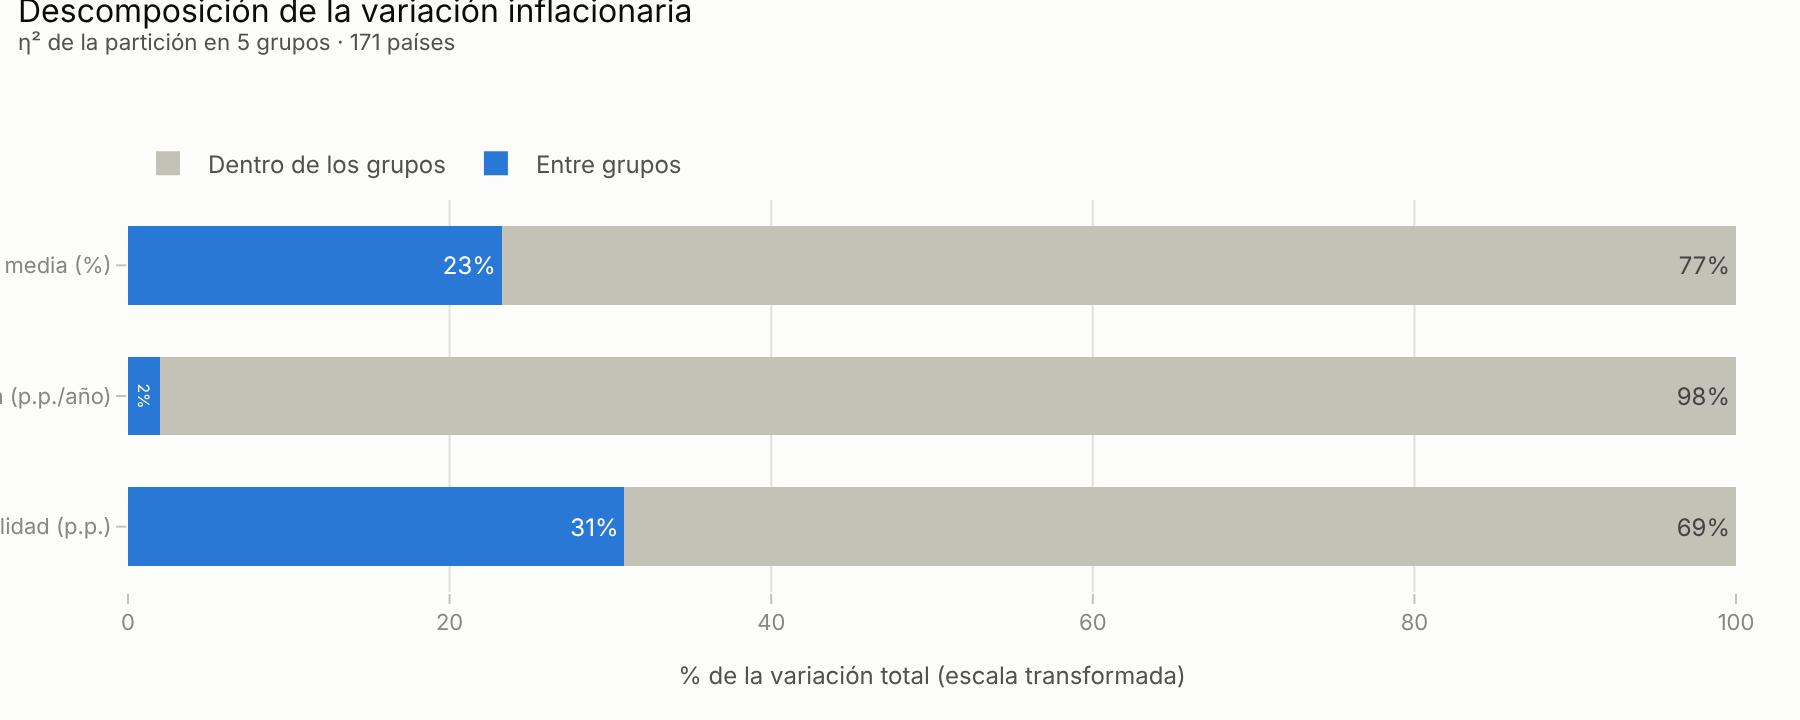

,estadistico,n,kruskal_H,kruskal_p,epsilon2,eta2_transformado,p_permutacion,no_explicado_pct
0,media,171,46.202,0.000,0.272,0.233,2.000e-04,76.749
1,tendencia,171,6.723,0.151,0.040,0.020,5.169e-01,98.035
2,volatilidad,171,66.827,0.000,0.393,0.309,2.000e-04,69.126


In [8]:
tests = pd.read_csv(D / "h1_tests.csv")
fig = go.Figure()
fig.add_bar(y=[TIT[s] for s in tests["estadistico"]], x=100 * tests["eta2_transformado"], orientation="h", name="Entre grupos",
            marker_color=CATEGORICAL[0], text=(100 * tests["eta2_transformado"]).round(0).astype(int).astype(str) + "%", textposition="inside")
fig.add_bar(y=[TIT[s] for s in tests["estadistico"]], x=100 * (1 - tests["eta2_transformado"]), orientation="h", name="Dentro de los grupos",
            marker_color="#c3c2b7", text=(100 * (1 - tests["eta2_transformado"])).round(0).astype(int).astype(str) + "%", textposition="inside")
fig.update_layout(barmode="stack", bargap=0.4, xaxis=dict(title="% de la variación total (escala transformada)", range=[0, 100]),
                  yaxis=dict(autorange="reversed", showgrid=False),
                  title=subtitle("Descomposición de la variación inflacionaria", "η² de la partición en 5 grupos · 171 países"))
show(fig, "06_h1_descomposicion", height=360)
tests[["estadistico", "n", "kruskal_H", "kruskal_p", "epsilon2", "eta2_transformado", "p_permutacion", "no_explicado_pct"]].round(4)

**Resultado de H1.** El grupo monetario-fiscal explica una parte significativa pero minoritaria de la variación inflacionaria: **23% de la inflación media** y **31% de la volatilidad** (p < 0,001 por permutación en ambos), y **2% de la tendencia** (no significativo, p = 0,52). Entre el 69% y el 98% de la variación ocurre **dentro** de los grupos.

**H1 se sostiene**: compartir un perfil monetario-fiscal acota en parte el nivel y la volatilidad de la inflación, pero no determina la trayectoria. Países con perfiles similares tienen inflaciones muy distintas, y la dirección de su trayectoria (tendencia) es independiente del perfil.

In [9]:
disp = pd.read_csv(D / "h1_dispersion.csv")
disp["grupo"] = disp["cluster"].map(lambda k: NAMES.get(int(k), k) if str(k).isdigit() else "Total")
tab = disp.pivot(index="grupo", columns="estadistico", values=["mediana", "ric", "min", "max"]).round(2)
tab = tab.reindex([NAMES[k] for k in order] + ["Total"])
tab

mediana                         ric            \
estadistico                   media tendencia volatilidad media tendencia   
grupo                                                                       
Avanzadas                      1.87     -0.09        0.85  0.54      0.09   
Ingreso medio                  4.44     -0.17        2.53  4.68      0.28   
Rentistas de recursos          3.86     -0.02        2.82  6.31      0.31   
Pequeñas con Estado grande     5.43     -0.21        2.82  1.37      0.31   
Baja profundidad financiera    6.44     -0.12        4.00  8.45      0.22   
Total                          3.86     -0.12        2.47  4.87      0.25   

                                          min                          max  \
estadistico                 volatilidad media tendencia volatilidad  media   
grupo                                                                        
Avanzadas                          0.36  0.10     -0.37        0.59   3.14   
Ingreso medio                      2.08  1.24     -3.13        0.78  27.45   
Rentistas de recursos              3.63  0.36     -7.30        0.97  72.74   
Pequeñas con Estado grande         2.36  2.52     -0.45        1.32  12.26   
Baja profundidad financiera        2.70  1.62    -16.83        1.38  60.67   
Total                              2.73  0.10    -16.83        0.59  72.74   

                                                   
estadistico                 tendencia volatilidad  
grupo                                              
Avanzadas                        0.07        2.38  
Ingreso medio                    3.10       31.54  
Rentistas de recursos           26.08       59.09  
Pequeñas con Estado grande       0.01        8.99  
Baja profundidad financiera      3.68      116.81  
Total                           26.08      116.81

## 5. Sensibilidad de H1 a la configuración de clustering

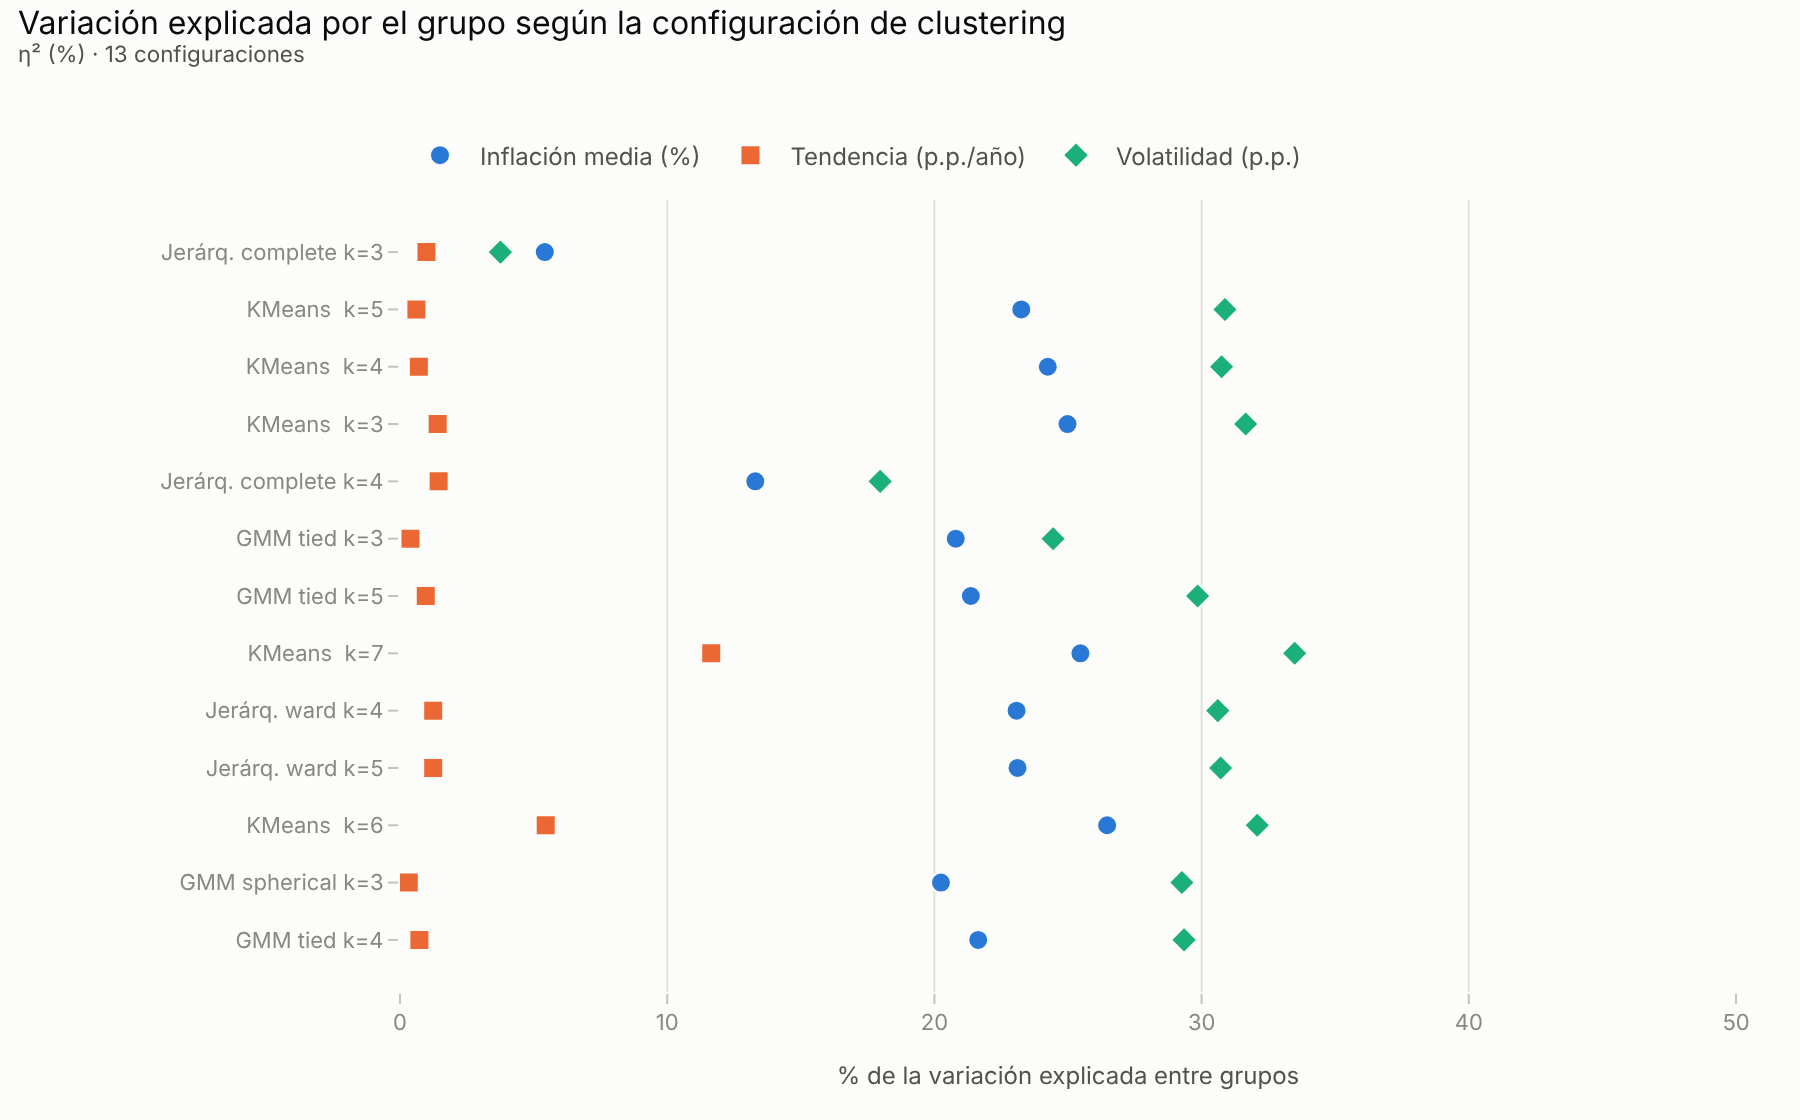

     eta2_media  eta2_tendencia  eta2_volatilidad
min         5.4             0.3               3.8
max        26.5            11.6              33.5


In [10]:
sens = pd.read_csv(D / "h1_sensibilidad.csv")
sens["config"] = sens["algoritmo"].str.replace("Jerarquico", "Jerárq.") + " " + sens["parametro"].replace("-", "") + " k=" + sens["k"].astype(str)
fig = go.Figure()
for i, stat in enumerate(["media", "tendencia", "volatilidad"]):
    fig.add_scatter(x=100 * sens[f"eta2_{stat}"], y=sens["config"], mode="markers", name=TIT[stat], marker=dict(size=10, color=CATEGORICAL[i],
                    symbol=["circle", "square", "diamond"][i]), hovertemplate="%{y} · " + stat + ": %{x:.1f}%<extra></extra>")
fig.update_layout(title=subtitle("Variación explicada por el grupo según la configuración de clustering", "η² (%) · 13 configuraciones"),
                  xaxis=dict(title="% de la variación explicada entre grupos", range=[0, 50]), yaxis=dict(autorange="reversed", showgrid=False),
                  margin=dict(l=200))
show(fig, "06_h1_sensibilidad", height=560)
print(sens[[f"eta2_{s}" for s in ["media", "tendencia", "volatilidad"]]].describe().loc[["min", "max"]].mul(100).round(1))

**Interpretación.** En las 8 configuraciones estables (ARI ≥ 0,60), la variación explicada por el grupo se mueve en un rango estrecho: 20-27% para la media, 0-12% para la tendencia y 29-34% para la volatilidad. Los valores más bajos de la tabla (5% y 4%) corresponden a soluciones jerárquicas inestables con grupos minúsculos. En ninguna configuración el grupo explica más de un tercio de la variación. **La conclusión de H1 no depende de qué algoritmo o qué k se elija.**

**Limitaciones.**

1. El espacio monetario arrastra parte del gradiente de desarrollo, por la presencia del gasto público en salud en el PC1 (notebook 05). Parte de la asociación entre grupo e inflación puede reflejar el desarrollo y no la política monetaria-fiscal en sentido estricto.
2. Los atípicos excluidos y los países sin IPC (entre ellos Argentina) son justamente los de trayectorias más extremas. Incluirlos aumentaría la heterogeneidad dentro de los grupos, así que la conclusión de H1 es conservadora.